In [1]:
!pip install yfinance pandas numpy matplotlib seaborn 

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [3]:
tickers = ['INFY.NS','^NSEI']
data = yf.download(tickers, period = '10Y', auto_adjust= True)
Data = data['Close']
Data.describe()

[*********************100%***********************]  2 of 2 completed


Ticker,INFY.NS,^NSEI
count,2473.000000,2468.000000
mean,1026.948618,16548.857221
std,445.835441,5709.784492
min,331.153748,7610.250000
25%,577.288940,10995.374756
50%,1140.914429,16614.399414
75%,1395.327759,22489.875488
max,1858.509033,26328.550781


In [4]:
clean_data = Data.dropna()
clean_data

Ticker,INFY.NS,^NSEI
Date,,
2016-11-21,340.232727,7929.100098
2016-11-22,341.390381,8002.299805
2016-11-23,343.649689,8033.299805
2016-11-24,347.402679,7965.500000
2016-11-25,365.028595,8114.299805
...,...,...
2026-11-16,1145.099976,25291.099609
2026-11-17,1130.000000,25387.400391
2026-11-18,1108.800049,25227.949219


In [5]:
returns = clean_data.pct_change()
returns = returns.dropna()
returns

Ticker,INFY.NS,^NSEI
Date,,
2016-11-22,0.003403,0.009232
2016-11-23,0.006618,0.003874
2016-11-24,0.010921,-0.008440
2016-11-25,0.050736,0.018681
2016-11-28,0.002302,0.001553
...,...,...
2026-11-16,0.003154,0.005838
2026-11-17,-0.013187,0.003808
2026-11-18,-0.018761,-0.006281


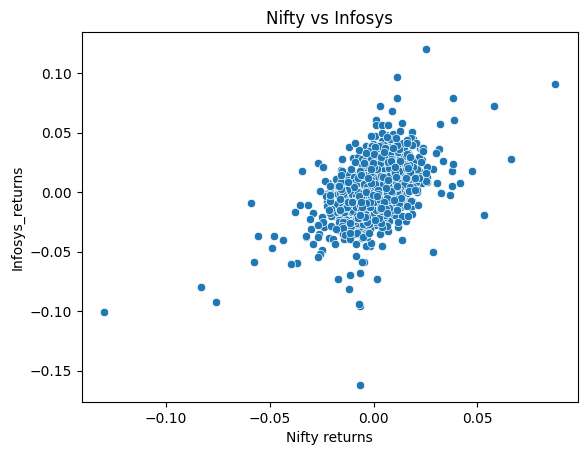

In [6]:
sns.scatterplot(data = returns, x = '^NSEI', y = 'INFY.NS')
plt.title("Nifty vs Infosys")
plt.xlabel("Nifty returns")
plt.ylabel("Infosys_returns")
plt.show()

In [7]:
x = returns['^NSEI']
x = sm.add_constant(x, prepend= False)
model = sm.OLS(returns['INFY.NS'], x)
res = model.fit()
res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                INFY.NS   R-squared:                       0.244
Model:                            OLS   Adj. R-squared:                  0.244
Method:                 Least Squares   F-statistic:                     796.1
Date:                Sun, 22 Nov 2026   Prob (F-statistic):          5.10e-152
Time:                        11:54:14   Log-Likelihood:                 6876.7
No. Observations:                2467   AIC:                        -1.375e+04
Df Residuals:                    2465   BIC:                        -1.374e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
^NSEI          0.8294      0.029     28.215      0.000       0.772       0.887
const          0.0002      0.000      0.607      0.544      -0.000       0.001
==============================================================================
Omnibus:                      474.627   Durbin-Watson:                   1.971
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             8188.222
Skew:                          -0.406   Prob(JB):                         0.00
Kurtosis:                      11.888   Cond. No.                         97.9
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

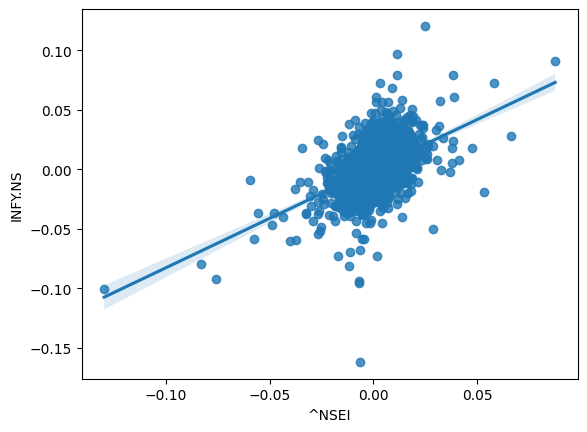

In [8]:
sns.regplot(data = returns, x = returns['^NSEI'], y = returns['INFY.NS'])
plt.show()